In [1]:
import dsi
import numpy as np

In [4]:
import matplotlib.pyplot as plt
import numpy as np

ROTATION = 0

# Font nativo LaTeX Computer Modern
plt.rcParams.update({
    "font.family": "serif",
    "mathtext.fontset": "cm",
})

def plot_full_page_comparison(
    categories: list[str],
    series_data: dict[str, list[float | int]],
    xlabel: str = "Mantissa",
    colors: list[str] | None = None,
    row_height: float = 0.70,  # Altezza ideale per pagina intera (A4/Letter)
    fig_width: float = 10.5,   # Larghezza distesa a doppia colonna
    dpi: int = 300
) -> tuple[plt.Figure, plt.Axes]:
    
    if colors is None:
        colors = ["#1f4e79", "#2e75b6", "#9dc3e6"]

    n_cats = len(categories)
    series_keys = list(series_data.keys())
    n_series = len(series_keys)

    data_matrix = np.array([series_data[k] for k in series_keys], dtype=float).T

    # Normalizzazione dell'esponente comune per categoria
    max_per_row = np.max(np.abs(data_matrix), axis=1)
    exponents = np.where(max_per_row > 0, np.floor(np.log10(max_per_row)).astype(int), 0)
    scaled_matrix = data_matrix / (10.0 ** exponents[:, None])

    # Etichette asse Y con esponente in math mode
    y_labels = [
        rf"{cat} ($\times 10^{{{exp}}}$)" if exp != 0 else rf"{cat}"
        for cat, exp in zip(categories, exponents)
    ]

    fig_height = max(8.0, n_cats * row_height)
    fig, ax = plt.subplots(figsize=(fig_width, fig_height), dpi=dpi)

    y_indices = np.arange(n_cats)
    total_group_height = 0.76
    bar_height = total_group_height / n_series
    offsets = np.linspace(
        -total_group_height / 2 + bar_height / 2,
        total_group_height / 2 - bar_height / 2,
        n_series
    )

    for i, series_name in enumerate(series_keys):
        bars = ax.barh(
            y_indices + offsets[i],
            scaled_matrix[:, i],
            height=bar_height,
            label=series_name,
            color=colors[i % len(colors)]
        )
        ax.bar_label(bars, fmt="%.2f", padding=5, fontsize=10)

    ax.set_yticks(y_indices)
    ax.set_yticklabels(y_labels, fontsize=11, rotation=ROTATION, ha="right")
    ax.set_xlabel(xlabel, fontsize=13, fontweight="bold")
    ax.margins(x=0.15)
    ax.invert_yaxis()
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.grid(axis="x", linestyle="--", alpha=0.35)

    # Legenda ordinata in alto a destra
    ax.legend(
        loc="upper right",
        frameon=True,
        framealpha=0.9,
        edgecolor="#d0d0d0",
        fontsize=11
    )

    plt.tight_layout()
    return fig, ax

In [5]:
datasets_names = [ "Abalone", "Airfoil self noise", "Auction verification", "Concrete compressive strength",
                   "Physiochemical protein", "Solar flare", "Naval propulsion plant", "White wine", "Red wine",
                   "Grid stability","California housing", "Cpu activity","Kin8nm","Pumadyn32nh", "Miami housing",
                   "Cps88wages", "Brazilian houses", "Health insurance", "Energy efficiency", "Forest fires", 
                   "Qsar fish toxicity", "Cars", "Space ga"]

DSI_RMSE = [ 2.3251, 3.3972, 3.2483e+03, 7.4873,
             4.1014,  8.4258e-01, 9.2945e-03, 6.7155e-01,
             6.0094e-01, 1.7063e-02, 6.3491e+04, 3.0645e+00, 
             1.2582e-01, 4.4085e-02, 1.0939e+05, 3.7521e+02,
             3.2210e+03, 1.5804e+01, 1.9428e+00, 3.0940e+00,
             9.4236e-01, 2.6092e+03, 1.1455e-01]

RF_RMSE = [ 2.133, 2.203, 2.972e+03,  0.529e1, #+1
            3.456, 8.004e-1, 0.112e-2, 5.937e-1, 
            5.614e-1, 1.280e-2, 5.050e4, 2.461,
            1.452e-1, 2.621e-2, 0.925e5, 3.830e2,
            0.587e4, 1.452e1, 1.082, 5.037e1,
            0.861, 2.486e3, 1.151e-1]

GAM = [ 2.120,  4.588, 6.140e+03,  0.963e1,
        4.951, 7.664e-1, 0.013e-2, 7.183e-1,
        6.508e-1, 1.711e-2, 6.193e4, 2.714,
        1.974e-1, 3.306e-2, 1.328e5, 3.856e2,
        0.321e4, 1.465e1, 2.934, 4.883e1,
        0.923,  2.935e3,  1.053e-1]

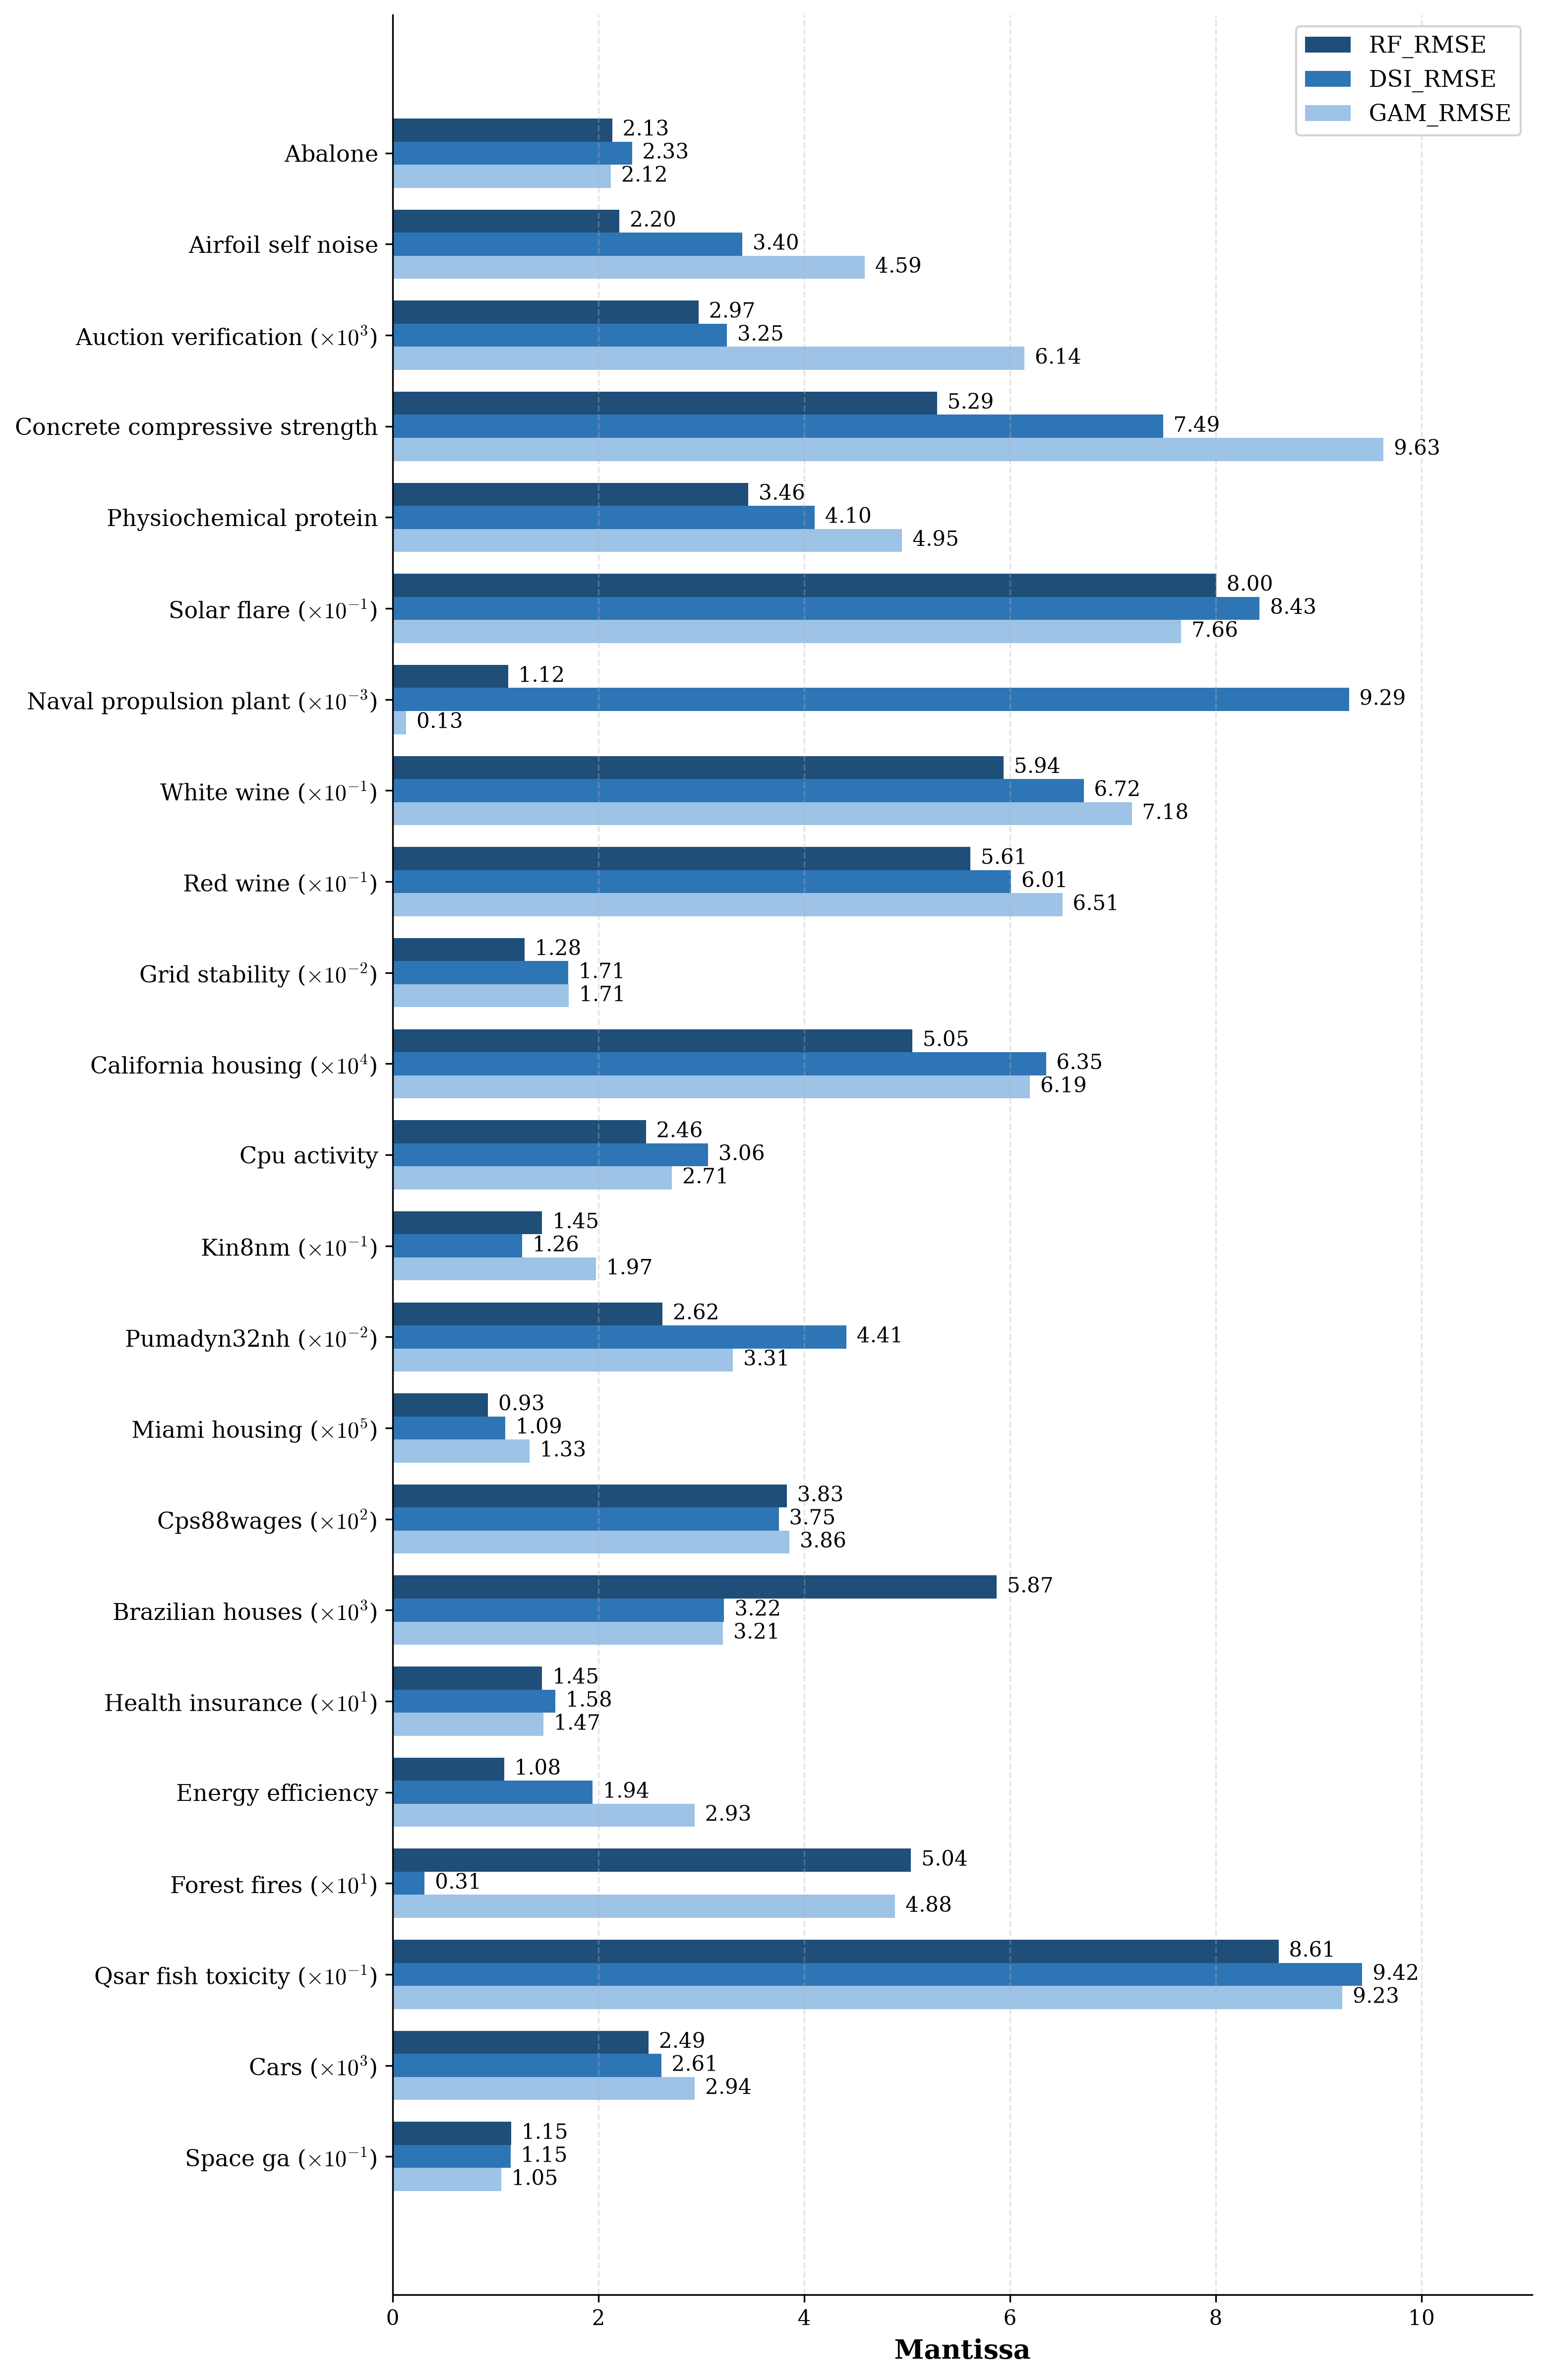

In [6]:
categories = datasets_names
data = {
    "RF_RMSE": RF_RMSE,
    "DSI_RMSE": DSI_RMSE,
    "GAM_RMSE": GAM
}

fig, ax = plot_full_page_comparison(categories, data)
plt.savefig("bar_plt.png")
plt.show()